In [34]:
using VoronoiMeshes,TensorsLite, TensorsLiteGeometry, ImmutableVectors, LinearAlgebra, NCDatasets, MPASTools
using StaticArrays, SparseArrays
using CairoMakie
include("juliaDEC.jl")

plot_cochain

In [35]:
mesh = VoronoiMesh("meshes/mesh6_regular.nc")

function rk4_step(f, u, t, dt)
    k1 = f(u, t)
    k2 = f(u + 0.5*dt*k1, t + 0.5*dt)
    k3 = f(u + 0.5*dt*k2, t + 0.5*dt)
    k4 = f(u + dt*k3, t + dt)
    return u + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)
end

function initial_condition1(x)
    xp = mesh.x_period
    yp = mesh.y_period
    center = [0.3, 0.5]
    sigma = 0.05

    x_vec = TensorsLite.Vec(x = x[1], y = x[2])
    center_vec = TensorsLite.Vec(x = center[1], y = center[2])
    x_raw = closest(center_vec, x_vec, xp, yp)
    y = [x_raw.x, x_raw.y]
    return exp(-(norm(y - center))^2/(2*sigma^2))
end

struct AdvectionProblem #we solve du/dt + iᵥ(du) = 0
    mesh::VoronoiMesh
    velocity::Function  # Vector field function
    rho::Float64
    initial_condition::Function
    dt::Float64
    T::Float64
end

In [36]:
velocity = x -> [1.0, 0.0]  # Constant field
reverse_velocity = x -> [-1.0, 0.0]
velocity2 = x -> [-sin(pi*x[1])^2*sin(2*pi*x[2]), sin(pi*x[2])^2*sin(2*pi*x[1])] # Non-constant field
reverse_velocity2 = x -> [sin(pi*x[1])^2*sin(2*pi*x[2]), -sin(pi*x[2])^2*sin(2*pi*x[1])]
rho = 1.0
T1 = 0.4
T2 = 2.0
dt = 0.001

p1 = AdvectionProblem(mesh, velocity, rho, initial_condition1, dt, T1)
p1_rev = AdvectionProblem(mesh, reverse_velocity, rho, initial_condition1, dt, T1)
p2 = AdvectionProblem(mesh, velocity2, rho, initial_condition1, dt, T2)
p2_rev = AdvectionProblem(mesh, reverse_velocity2, rho, initial_condition1, dt, T2)

u_initial_primal_0form = Cochain(initial_condition1.(mesh.cells.position), 0, true)
u_initial_dual_0form = Cochain(initial_condition1.(mesh.vertices.position), 0, false)
u_initial_dual_2form = Cochain(initial_condition1.(mesh.cells.position) .* mesh.cells.area, 2, false);

println("length of mesh = ", maximum(mesh.edges.lengthDual))

length of mesh = 0.010416666713911837


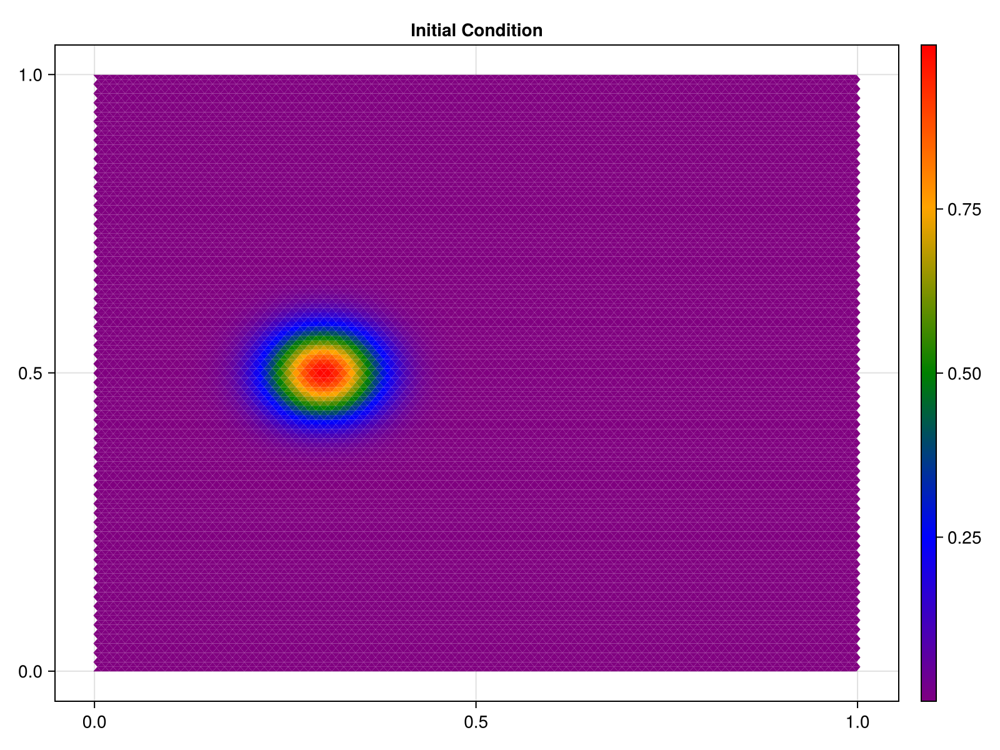

In [37]:
# Plot initial condition
fig = Figure(size=(800, 600))
ax = Axis(fig[1, 1], title = "Initial Condition")
fig, ax = plot_cochain(fig, ax, u_initial_primal_0form, mesh, :rainbow)
fig

## Caso 1 - Discretizando diretamente a equação de transporte:
$$
\frac{\partial u}{\partial t} + \text{div}(u\vec{v}) = 0
$$

Conisiderando que o campo vetorial é uma $1$-forma, reescrevemos o problema como

$$
\frac{\partial u}{\partial t} + \star d \star (u\wedge{v}) = 0.
$$

Utilizando os operadores DEC, resulta que
$$
\frac{\partial u_h}{\partial t} + \star_{2}^{\text{dual}} d_{1}^{\text{dual}}\star_{1}^{\text{primal}} W_v \,u_h  = 0,
$$
onde $W_v$ representa a discretização do produto $u \wedge v$.

### Transporte com campo constante

In [ ]:
# Initialize solution
problem = p1
u = Cochain(u_initial_primal_0form.values, 0, true)

# Precompute operators
v = discretize_vector_field_dual(problem.mesh, problem.velocity)
d1 = d1_matrix_dual(problem.mesh)
#star1 = star(problem.mesh, 1, true) 
star1 = hodge_star_lsq_matrix(problem.mesh, true, false)
star2 = star(problem.mesh, 2, false)
wedge10 = wedge_product_10_matrix(problem.mesh, v)

# Define the right-hand side function for RK4
function rhs(u_values, t)
    # Compute -iᵥ(du) = (-1)^(k(2-k)) *(*du ∧ v)
    return - star2 * d1 * star1 * wedge10 * u_values
end
t = 0.0
j = 0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(rhs, u.values, t, dt), 0, true)
    t += dt
    j += 1
    if j % 100 == 0
        println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
    end
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2,ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow);
maximum(abs.(u.values - u_initial_primal_0form.values))

In [ ]:
fig2

In [ ]:
fig3 = Figure()
ax3 = Axis(fig3[1, 1])
aux = Cochain(u_initial_primal_0form.values - u.values, 0, true)
fig3,ax3 = plot_cochain(fig3, ax3, aux, problem.mesh, :rainbow)

In [ ]:
fig3

### Avançando no tempo com campo reverso

In [ ]:
problem = p1_rev

# Precompute operators
v = discretize_vector_field_dual(problem.mesh, problem.velocity)
wedge10 = wedge_product_10_matrix(problem.mesh, v)

# Define the right-hand side function for RK4
function rhs(u_values, t)
    # Compute -iᵥ(du) = (-1)^(k(2-k)) *(*du ∧ v)
    return - star2 * d1 * star1 * wedge10 * u_values
end
t = 0.0
j = 0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(rhs, u.values, t, dt), 0, true)
    t += dt
    j += 1
    if j % 100 == 0
        println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
    end
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2,ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow);
maximum(abs.(u.values - u_initial_primal_0form.values))

In [ ]:
fig2

### Transporte com campo não constante

In [9]:
# Define problem
problem = p2

# Initialize solution
u = Cochain(u_initial_primal_0form.values, 0, true)

# Precompute operators
v = discretize_vector_field_dual(problem.mesh, problem.velocity)
wedge10 = wedge_product_10_matrix(problem.mesh, v)

# Define the right-hand side function for RK4
function rhs(u_values, t)
    # Compute -iᵥ(du) = (-1)^(k(2-k)) *(*du ∧ v)
    return - star2 * d1 * star1 * wedge10 * u_values
end
t = 0.0
j = 0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(rhs, u.values, t, dt), 0, true)
    t += dt
    j += 1
    if j % 100 == 0
        println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
    end
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2,ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow);
println("Erro na norma Infinito:")
maximum(abs.(u.values - u_initial_primal_0form.values))


t = 0.10000000000000007, max value = 0.9967028577436335,   min value = -3.256380543753703e-23
t = 0.20000000000000015, max value = 0.9971040977849935,   min value = -4.841040025915021e-15
t = 0.3000000000000002, max value = 1.0035781857924932,   min value = -4.98254028558507e-13
t = 0.4000000000000003, max value = 1.0020472986449709,   min value = -7.526385068068571e-13
t = 0.5000000000000003, max value = 1.005756337016425,   min value = -2.9368687749526953e-5
t = 0.6000000000000004, max value = 1.0067259777692825,   min value = -0.0003503091905452587
t = 0.7000000000000005, max value = 1.009754138857795,   min value = -0.004068140893899147
t = 0.8000000000000006, max value = 1.0088735672108295,   min value = -0.014065227340612194
t = 0.9000000000000007, max value = 1.0065553222478472,   min value = -0.033391794313912634
t = 1.0000000000000007, max value = 1.0040369277744177,   min value = -0.0560978331321743
t = 1.0999999999999897, max value = 0.9934103098727627,   min value = -0.0859

0.9909642041166185

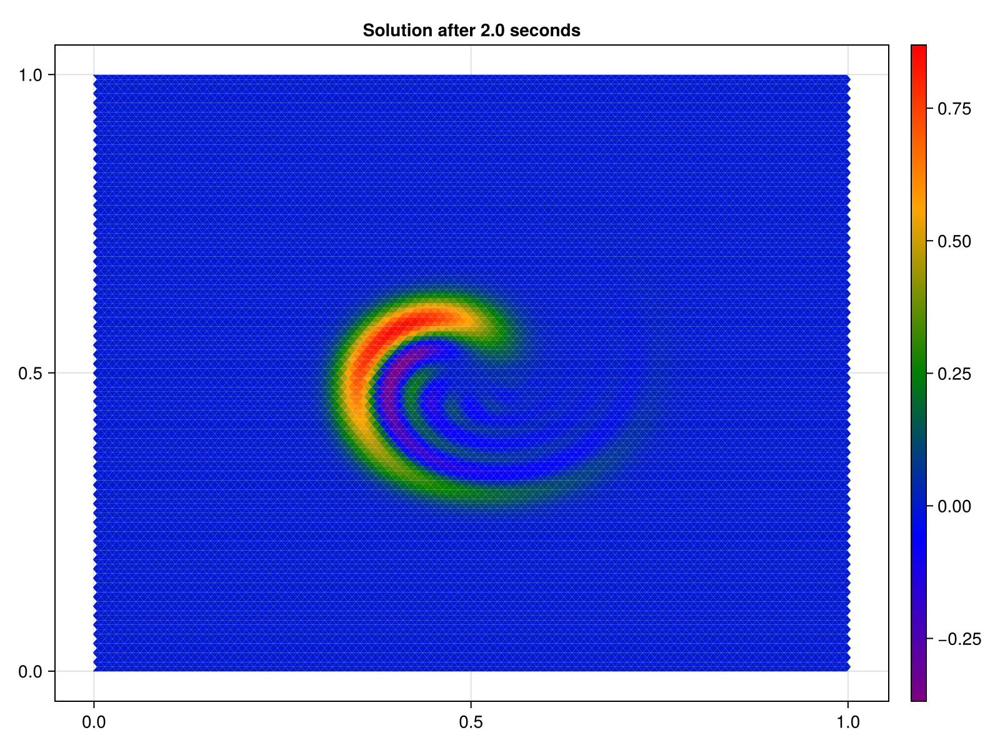

In [10]:
fig2

#### Utilizando u encontrado como condição inicial e "voltando para trás."

In [11]:
problem = p2_rev

# Precompute operators
v = discretize_vector_field_dual(problem.mesh, problem.velocity)
wedge10 = wedge_product_10_matrix(problem.mesh, v)

# Define the right-hand side function for RK4
function rhs(u_values, t)
    # Compute -iᵥ(du) = (-1)^(k(2-k)) *(*du ∧ v)
    return - star2 * d1 * star1 * wedge10 * u_values
end
t = 0.0
j = 0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(rhs, u.values, t, dt), 0, true)
    t += dt
    j += 1
    if j % 100 == 0
        println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
    end
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2,ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow);
println("Erro na norma Infinito:")
println(maximum(abs.(u.values - u_initial_primal_0form.values)))

t = 0.10000000000000007, max value = 0.889037014365033,   min value = -0.3522061813827449
t = 0.20000000000000015, max value = 0.907681575431698,   min value = -0.32356218217464794
t = 0.3000000000000002, max value = 0.9200938429464297,   min value = -0.29897950158385855
t = 0.4000000000000003, max value = 0.9374767413816794,   min value = -0.27033187394458946
t = 0.5000000000000003, max value = 0.9482615444179372,   min value = -0.2350944363388814
t = 0.6000000000000004, max value = 0.9613877523308353,   min value = -0.20741985802475438
t = 0.7000000000000005, max value = 0.9714652632042027,   min value = -0.1642274901536227
t = 0.8000000000000006, max value = 0.9837325742975944,   min value = -0.1253667995144053
t = 0.9000000000000007, max value = 0.9934103095524031,   min value = -0.08592037912555694
t = 1.0000000000000007, max value = 1.004036926959591,   min value = -0.05609783357687117
t = 1.0999999999999897, max value = 1.0065553210932885,   min value = -0.03339179476300426
t = 

In [12]:
fig3 = Figure()
ax3 = Axis(fig3[1, 1])
aux = Cochain(u_initial_primal_0form.values - u.values, 0, true)
fig3,ax3 = plot_cochain(fig3, ax3, aux, problem.mesh, :rainbow)

(Scene (600px, 450px):
  0 Plots
  2 Child Scenes:
    ├ Scene (600px, 450px)
    └ Scene (600px, 450px), Axis (24576 plots))

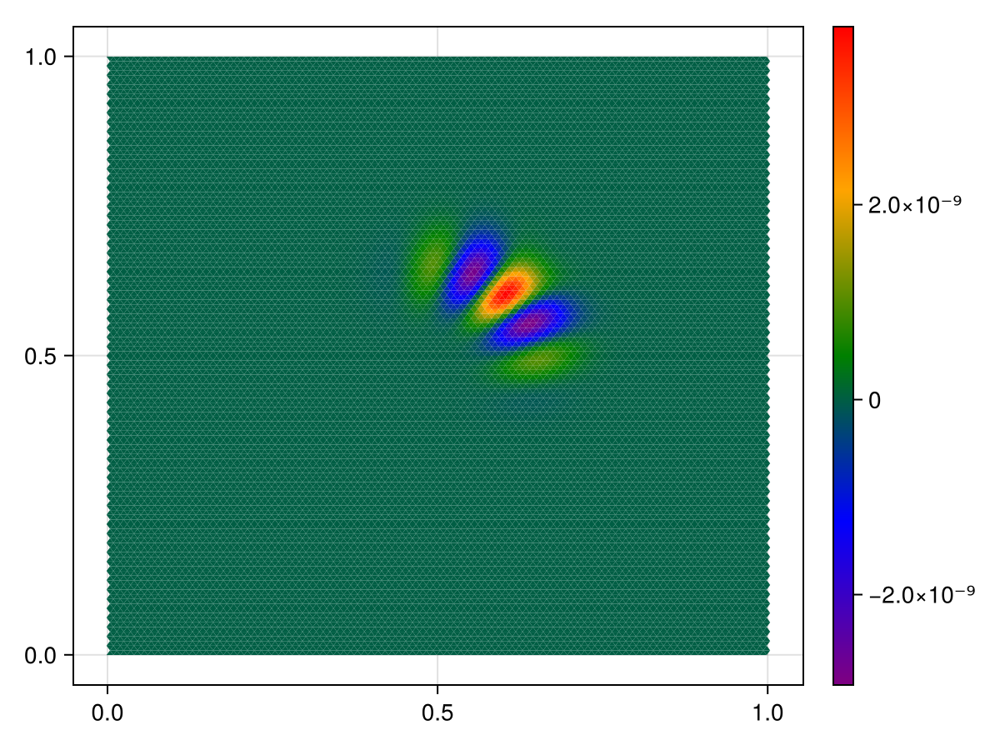

In [13]:
fig3

### Caso 2 - Discretizando o problema de transporte de Lie com 2-forma dual:
$$
\frac{\partial u_h}{\partial t} + \mathcal{L}_v u = 0,
$$
onde $ \mathcal{L}_v u = i_v(du) + d i_v (u)$. Tome $u_h$ uma $2$-forma discreta dual. Então, resolvemos o problema
$$
\frac{\partial u_h}{\partial t} + (-1)^{k(2-k)} d \star (\star u \wedge v) = 0.
$$
Dessa forma, temos que
$$
\frac{\partial u_h}{\partial t} + d_1^{dual} \star_1^{primal} W_v \star_2^{dual} u_h  = 0.
$$


### Transporte com campo constante

In [14]:
problem = p1
# Initialize solution
u = Cochain(u_initial_dual_2form.values, 2, false)

v = discretize_vector_field_dual(problem.mesh, problem.velocity)
d1 = d1_matrix_dual(problem.mesh)
#star1 = star(problem.mesh, 1, true)
star1 = hodge_star_lsq_matrix(problem.mesh, true, false)
star2 = star(problem.mesh, 2, false)
wedge10 = wedge_product_10_matrix(problem.mesh, v)
# Define the right-hand side function for RK4
function rhs(u_values, t)
    # Compute -iᵥ(du) = (-1)^(k(2-k)) *(*du ∧ v)
    return  -d1 * star1 * wedge10 * star2 * u_values
end
t = 0.0
j = 0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(rhs, u.values, t, dt), 2, false)
    t += dt
    j += 1
    if j % 100 == 0
        println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
    end
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2, ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow)
println("Erro na norma Infinito:")
maximum(abs.(u.values - u_initial_dual_2form.values))

t = 0.10000000000000007, max value = 8.111720388811967e-5,   min value = -1.3325993032180613e-19
t = 0.20000000000000015, max value = 8.123027799918709e-5,   min value = -2.5755816241859633e-12
t = 0.3000000000000002, max value = 8.068747636108419e-5,   min value = -9.789535001097051e-10
t = 0.4000000000000003, max value = 8.087342354707806e-5,   min value = -1.772446160718231e-8
t = 0.5000000000000003, max value = 8.046760619064449e-5,   min value = -9.304880241438797e-8
t = 0.6000000000000004, max value = 8.026274786765525e-5,   min value = -2.6661120972618535e-7
t = 0.7000000000000005, max value = 7.998913387553636e-5,   min value = -5.535920155130699e-7
t = 0.8000000000000006, max value = 7.948490469190319e-5,   min value = -9.255380969145706e-7
t = 0.9000000000000007, max value = 7.933013117656409e-5,   min value = -1.4006163131757714e-6
t = 1.0000000000000007, max value = 7.86106307567163e-5,   min value = -1.9146804083670047e-6
t = 1.0999999999999897, max value = 7.8556108243212

2.6711372164338364e-5

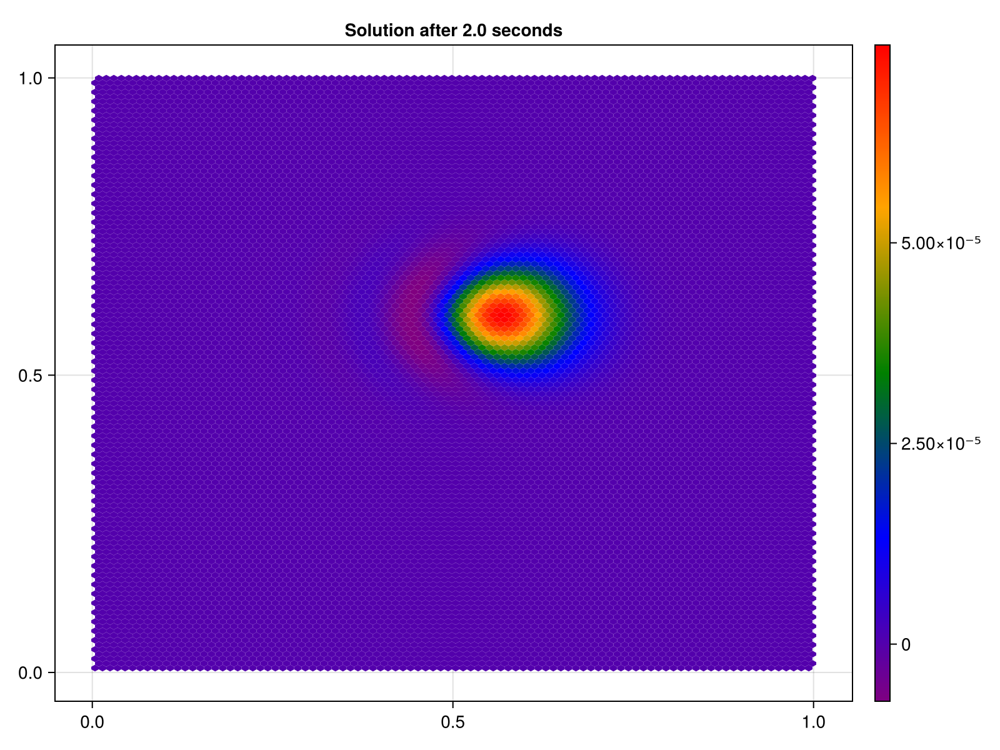

In [15]:
fig2

In [16]:
fig3 = Figure()
ax3 = Axis(fig3[1, 1])
aux = Cochain(u_initial_dual_2form.values - u.values, 2, false)
fig3,ax3 = plot_cochain(fig3, ax3, aux, problem.mesh, :rainbow)

(Scene (600px, 450px):
  0 Plots
  2 Child Scenes:
    ├ Scene (600px, 450px)
    └ Scene (600px, 450px), Axis (12288 plots))

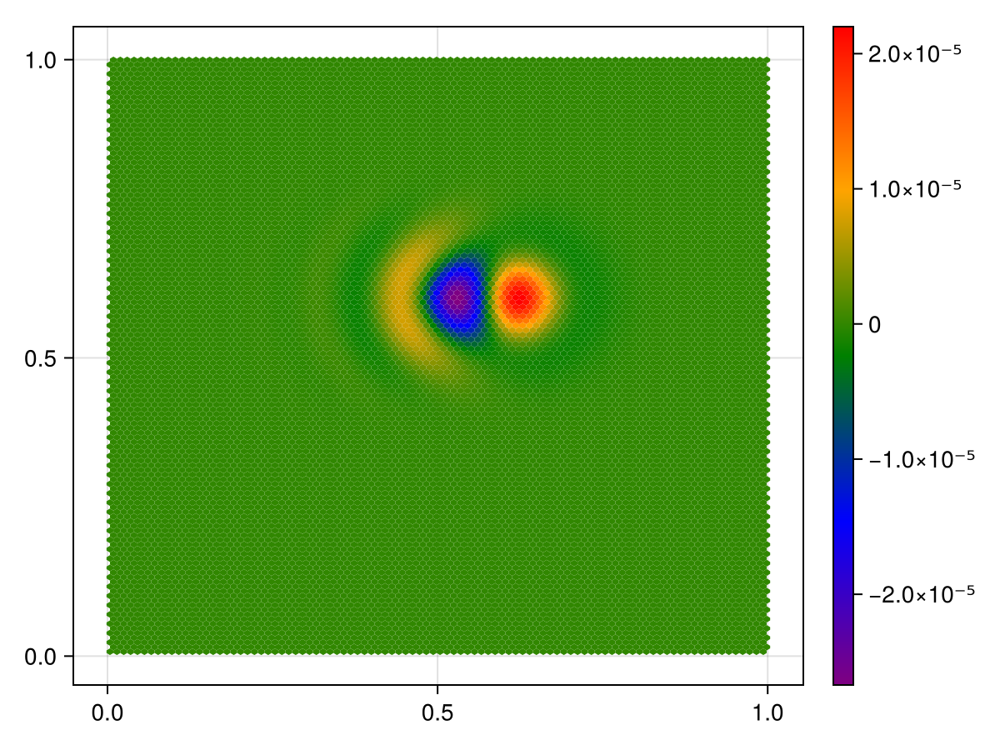

In [17]:
fig3

### Teste com campo não constante

In [18]:
problem = p2

# Initialize solution
u = Cochain(u_initial_dual_2form.values, 2, false)
v = discretize_vector_field_dual(problem.mesh, problem.velocity)

d1 = d1_matrix_dual(problem.mesh)
#star1 = star(problem.mesh, 1, true)
star1 = hodge_star_lsq_matrix(problem.mesh, true, false)
star2 = star(problem.mesh, 2, false)
wedge10 = wedge_product_10_matrix(problem.mesh, v)
# Define the right-hand side function for RK4
function rhs(u_values, t)
    # Compute -iᵥ(du) = (-1)^(k(2-k)) *(*du ∧ v)
    return  -d1 * star1 * wedge10 * star2 * u_values
end
t = 0.0
j = 0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(rhs, u.values, t, dt), 2, false)
    t += dt
    j += 1
    if j % 100 == 0
        println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
    end
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2, ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow);

t = 0.10000000000000007, max value = 8.111188623600775e-5,   min value = -2.6500492710729473e-27
t = 0.20000000000000015, max value = 8.114453917932316e-5,   min value = -3.939577872549165e-19
t = 0.3000000000000002, max value = 8.167140178392031e-5,   min value = -4.054795097015075e-17
t = 0.4000000000000003, max value = 8.154681784872456e-5,   min value = -6.124504004918931e-17
t = 0.5000000000000003, max value = 8.184866018722635e-5,   min value = -2.3900299280505257e-9
t = 0.6000000000000004, max value = 8.192756977914443e-5,   min value = -2.8508234888879933e-8
t = 0.7000000000000005, max value = 8.217400217356449e-5,   min value = -3.3106615325493837e-7
t = 0.8000000000000006, max value = 8.210234104776462e-5,   min value = -1.1446311309379982e-6
t = 0.9000000000000007, max value = 8.191368181059872e-5,   min value = -2.717431177369849e-6
t = 1.0000000000000007, max value = 8.170873438641661e-5,   min value = -4.565253345292051e-6
t = 1.0999999999999897, max value = 8.08439380325

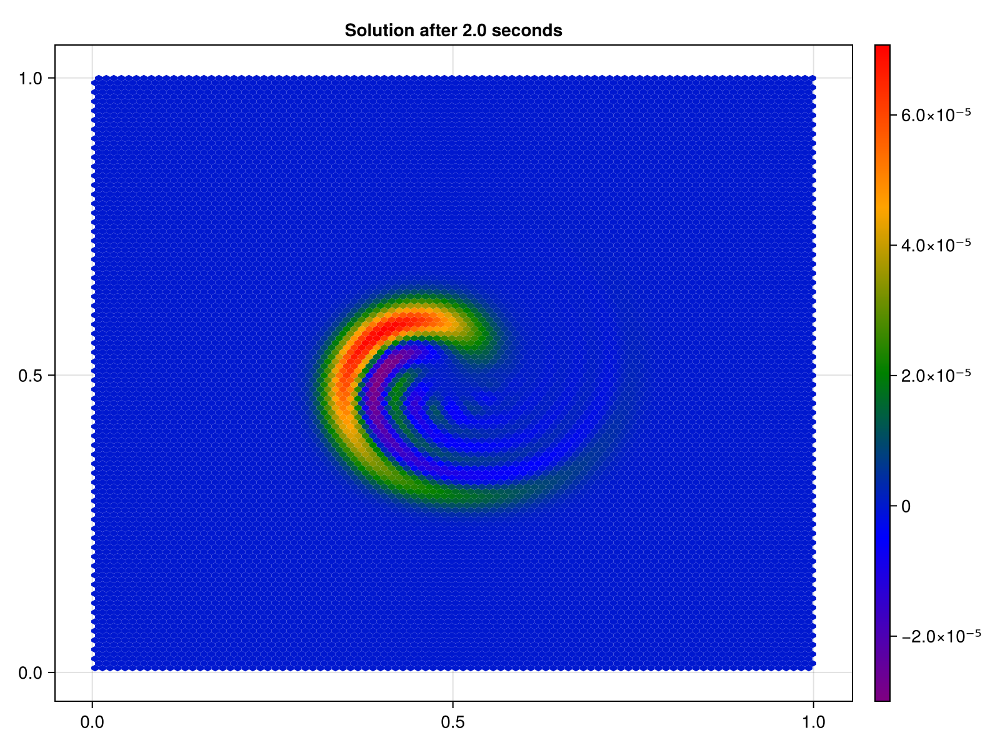

In [19]:
fig2

### Voltando para trás com campo não constante

In [20]:
problem = p2_rev

v = discretize_vector_field_dual(problem.mesh, problem.velocity)
wedge10 = wedge_product_10_matrix(problem.mesh, v)
# Define the right-hand side function for RK4
function rhs(u_values, t)
    # Compute -iᵥ(du) = (-1)^(k(2-k)) *(*du ∧ v)
    return  -d1 * star1 * wedge10 * star2 * u_values
end
t = 0.0
j = 0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(rhs, u.values, t, dt), 2, false)
    t += dt
    j += 1
    if j % 100 == 0
        println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
    end
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2, ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow);
println("Erro na norma Infinito:")
maximum(abs.(u.values - u_initial_dual_2form.values))

t = 0.10000000000000007, max value = 7.235001742775443e-5,   min value = -2.866261240458221e-5
t = 0.20000000000000015, max value = 7.386731568775417e-5,   min value = -2.6331557777611607e-5
t = 0.3000000000000002, max value = 7.487742858594758e-5,   min value = -2.433101410734256e-5
t = 0.4000000000000003, max value = 7.629205245391845e-5,   min value = -2.199966420532943e-5
t = 0.5000000000000003, max value = 7.716972197697477e-5,   min value = -1.913203420041662e-5
t = 0.6000000000000004, max value = 7.82379355364495e-5,   min value = -1.6879871262495952e-5
t = 0.7000000000000005, max value = 7.905804550600707e-5,   min value = -1.33648673696611e-5
t = 0.8000000000000006, max value = 8.005636188332321e-5,   min value = -1.0202376268418966e-5
t = 0.9000000000000007, max value = 8.084393800650192e-5,   min value = -6.992218354426507e-6
t = 1.0000000000000007, max value = 8.170873432010586e-5,   min value = -4.565253381481574e-6
t = 1.0999999999999897, max value = 8.191368171664044e-5,

3.1133956361357323e-13

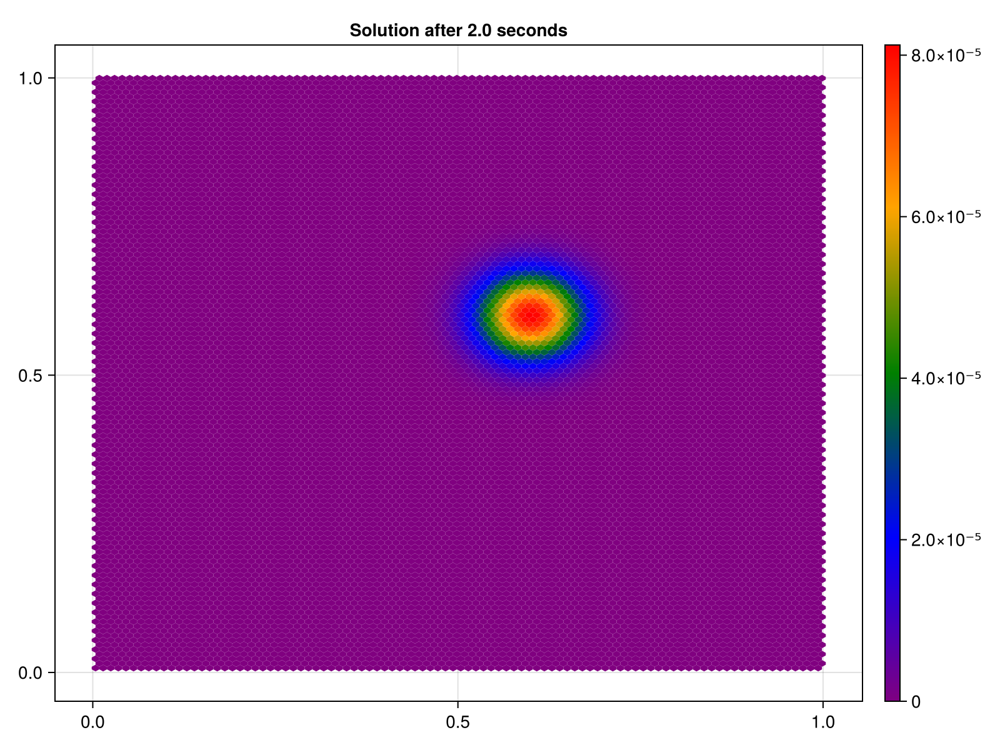

In [21]:
fig2

In [22]:
fig3 = Figure()
ax3 = Axis(fig3[1, 1])
aux = Cochain(u_initial_dual_2form.values - u.values, 2, false)
fig3,ax3 = plot_cochain(fig3, ax3, aux, problem.mesh, :rainbow)

(Scene (600px, 450px):
  0 Plots
  2 Child Scenes:
    ├ Scene (600px, 450px)
    └ Scene (600px, 450px), Axis (12288 plots))

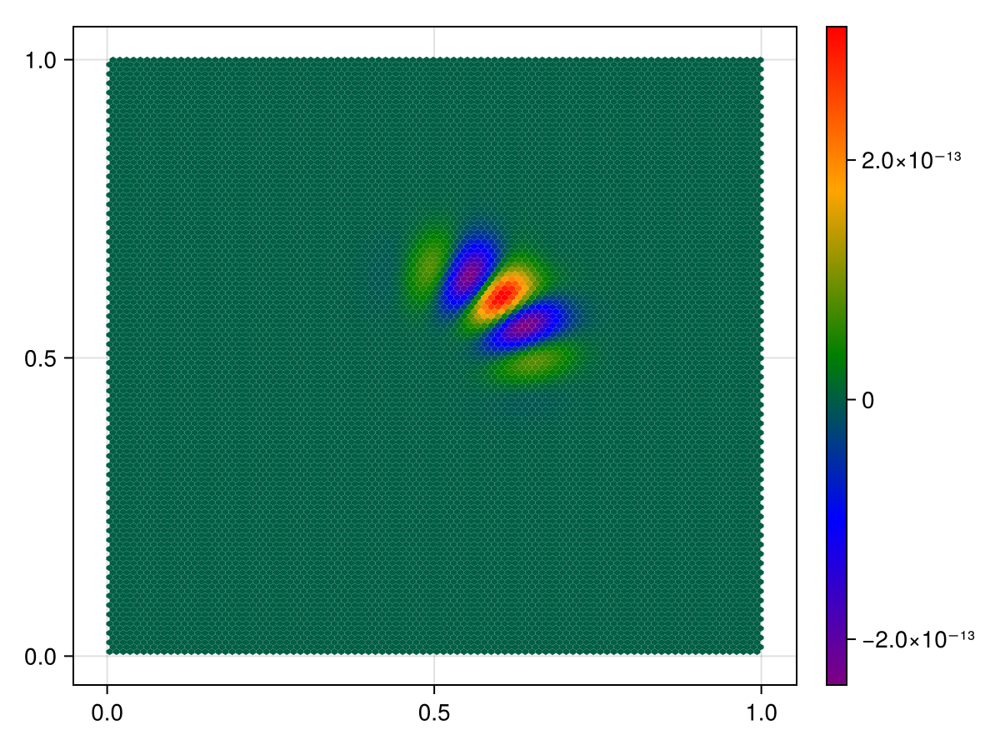

In [23]:
fig3

### Caso 3 - Discretizando o problema de transporte de Lie com 0-forma dual:
$$
\frac{\partial u_h}{\partial t} + \mathcal{L}_v u = 0,
$$
onde $ \mathcal{L}_v u = i_v(du) + d i_v (u)$. Tome $u_h$ uma $0$-forma discreta dual. Então, resolvemos o problema
$$
\frac{\partial u_h}{\partial t} + (-1)^{k(2-k)} \star (\star d u \wedge v) = 0.
$$
Dessa forma, temos que
$$
\frac{\partial u_h}{\partial t} - \star_2^{primal} W_v \star_1^{\text{dual}} d_0^{\text{dual}} u_h  = 0.
$$


### Transporte com campo constante

In [24]:
problem = p1

# Initialize solution
u = Cochain(u_initial_dual_0form.values, 0, false)
v = discretize_vector_field_dual(problem.mesh, problem.velocity)
d0 = d0_matrix_dual(problem.mesh)
star2 = star(problem.mesh, 2, true)
#star1 = star(problem.mesh, 1, false)
star1 = hodge_star_lsq_matrix(problem.mesh, false, false)
wedge11 = wedge_product_11_matrix(problem.mesh, v)

# iᵥ(du)
f(u_values, t) = star2 * wedge11 * star1 * d0 * u_values

t = 0.0
j = 0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(f, u.values, t, dt), 0, false)
    t += dt
    j += 1
    if j % 100 == 0
        println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
    end
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2, ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow);
println("Erro na norma Infinito:")
maximum(abs.(u.values - u_initial_dual_0form.values))

t = 0.10000000000000007, max value = 0.9968444373003535,   min value = -0.020778852512877675
t = 0.20000000000000015, max value = 0.9971176318931264,   min value = -0.0210377605514867
t = 0.3000000000000002, max value = 0.9972141204617957,   min value = -0.02096931219170276
t = 0.4000000000000003, max value = 0.997136049204779,   min value = -0.020699547627042666
t = 0.5000000000000003, max value = 0.9949579873225822,   min value = -8.90556719471898e-7
t = 0.6000000000000004, max value = 0.9964531036485306,   min value = -0.020978663620000695
t = 0.7000000000000005, max value = 0.9958520671228513,   min value = -0.02093951720327351
t = 0.8000000000000006, max value = 0.9950793171983745,   min value = -0.020990234165070752
t = 0.9000000000000007, max value = 0.994134576970843,   min value = -0.0204710688742455
t = 1.0000000000000007, max value = 0.994889148097828,   min value = -0.00015899003728879965
t = 1.0999999999999897, max value = 0.9924713056081494,   min value = -0.0209646630339

0.10292383960248508

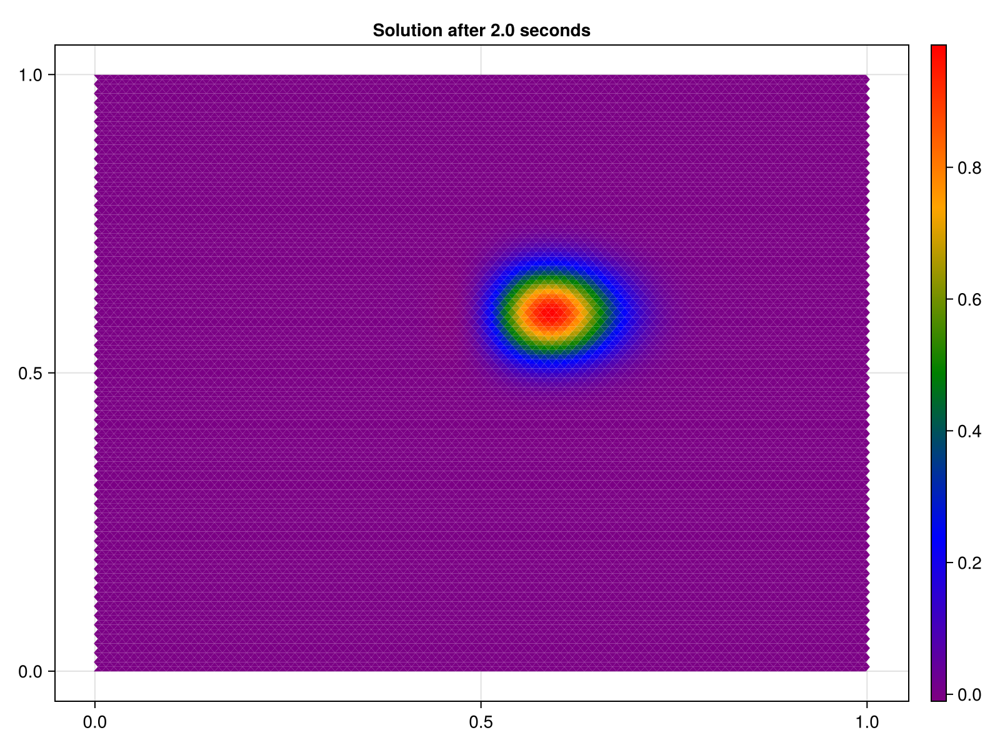

In [25]:
fig2

In [26]:
fig3 = Figure()
ax3 = Axis(fig3[1, 1])
aux = Cochain(u_initial_dual_0form.values - u.values, 0, false)
fig3,ax3 = plot_cochain(fig3, ax3, aux, problem.mesh, :rainbow)

(Scene (600px, 450px):
  0 Plots
  2 Child Scenes:
    ├ Scene (600px, 450px)
    └ Scene (600px, 450px), Axis (24576 plots))

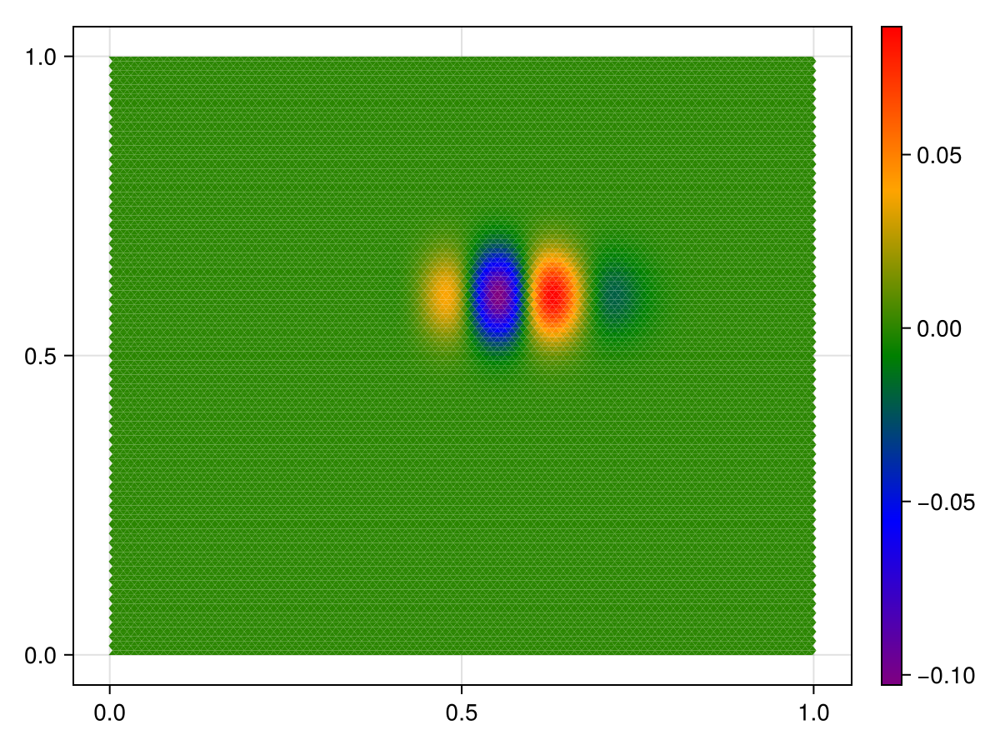

In [27]:
fig3

### Teste com campo não constante

In [28]:
problem = p2

# Initialize solution
u = Cochain(u_initial_dual_0form.values, 0, false)
v = discretize_vector_field_dual(problem.mesh, problem.velocity)
d0 = d0_matrix_dual(problem.mesh)
star2 = star(problem.mesh, 2, true)
#star1 = star(problem.mesh, 1, false)
star1 = hodge_star_lsq_matrix(problem.mesh, false, false)
wedge11 = wedge_product_11_matrix(problem.mesh, v)

# iᵥ(du)
f(u_values, t) = star2 * wedge11 * star1 * d0 * u_values

t = 0.0
j = 0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(f, u.values, t, dt), 0, false)
    t += dt
    j += 1
    if j % 100 == 0
        println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
    end
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2, ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow);
println("Erro na norma Infinito:")
maximum(abs.(u.values - u_initial_dual_0form.values))

t = 0.10000000000000007, max value = 0.9597619609349528,   min value = -0.023701606632649672
t = 0.20000000000000015, max value = 0.8529645757862441,   min value = -0.05895017690580981
t = 0.3000000000000002, max value = 0.9666403709979245,   min value = -0.12695279381558466
t = 0.4000000000000003, max value = 1.0240563276145733,   min value = -0.27238017075408455
t = 0.5000000000000003, max value = 1.0823026629460406,   min value = -0.6768464255935907
t = 0.6000000000000004, max value = 2.0984349591923004,   min value = -2.749305350339938
t = 0.7000000000000005, max value = 18.91993036043545,   min value = -20.095477810403445
t = 0.8000000000000006, max value = 249.48769332303817,   min value = -223.9431323481945
t = 0.9000000000000007, max value = 4430.5610505314635,   min value = -3843.900402888577
t = 1.0000000000000007, max value = 96992.59597488263,   min value = -80914.90903426817
t = 1.0999999999999897, max value = 2.61892478784558e6,   min value = -2.3096724665427585e6
t = 1.1

1.8076865246605292e22

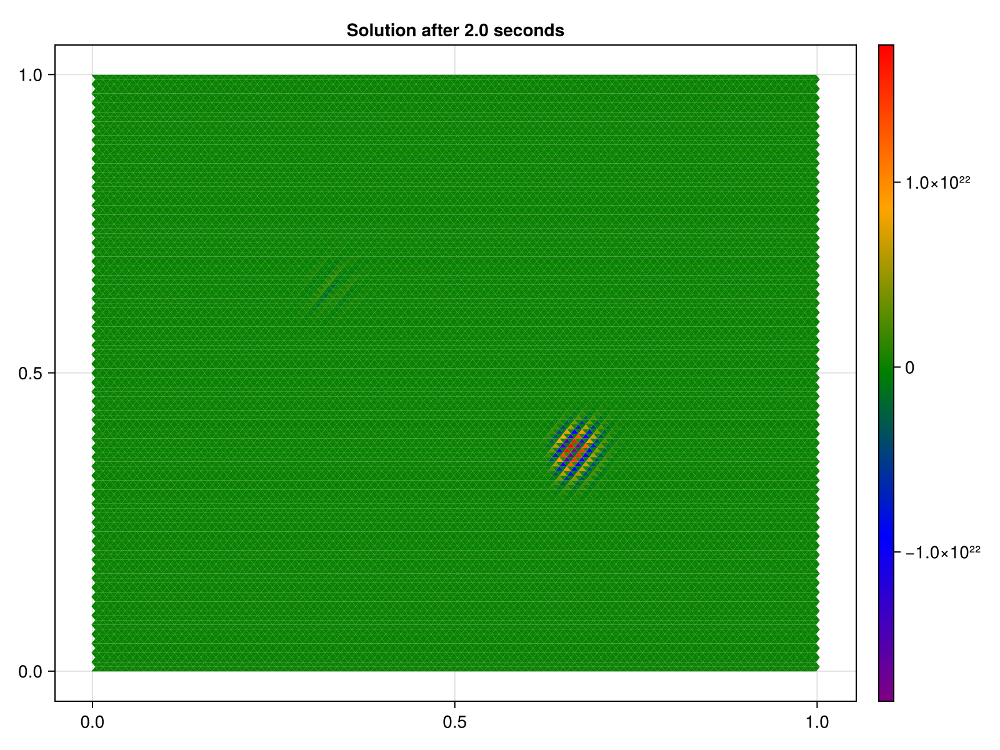

In [29]:
fig2

### Voltando para trás com campo não constante

In [30]:
problem = p2_rev

v = discretize_vector_field_dual(problem.mesh, problem.velocity)
wedge11 = wedge_product_11_matrix(problem.mesh, v)

# iᵥ(du)
f(u_values, t) = star2 * wedge11 * star1 * d0 * u_values

t = 0.0
while t < problem.T
    dt = min(problem.dt, problem.T - t)
    u = Cochain(rk4_step(f, u.values, t, dt), 0, false)
    t += dt
    println("t = $t, max value = $(maximum(u.values)),   min value = $(minimum(u.values))")
end

fig2 = Figure(size=(800, 600))
ax2 = Axis(fig2[1, 1], title = "Solution after $T seconds")
fig2, ax2 = plot_cochain(fig2, ax2, u, problem.mesh, :rainbow);
println("Erro na norma Infinito:")
maximum(abs.(u.values - u_initial_dual_0form.values))

t = 0.001, max value = 1.6725316518715297e22,   min value = -1.7346900721840029e22
t = 0.002, max value = 1.6055563364233525e22,   min value = -1.6646416214479977e22
t = 0.003, max value = 1.541263646780545e22,   min value = -1.597422102860112e22
t = 0.004, max value = 1.4795461074994982e22,   min value = -1.5329172565619349e22
t = 0.005, max value = 1.4203005500012553e22,   min value = -1.4710174381221117e22
t = 0.006, max value = 1.363427939941967e22,   min value = -1.4116174320800035e22
t = 0.007, max value = 1.3088332115043672e22,   min value = -1.3546162730227236e22
t = 0.008, max value = 1.2564251083327289e22,   min value = -1.2999170738911414e22
t = 0.009000000000000001, max value = 1.206116030844892e22,   min value = -1.2474268612227586e22
t = 0.010000000000000002, max value = 1.157821889665643e22,   min value = -1.1970564170511555e22
t = 0.011000000000000003, max value = 1.1114619649359773e22,   min value = -1.1487201271930386e22
t = 0.012000000000000004, max value = 1.0669587

6.444692496857685e33

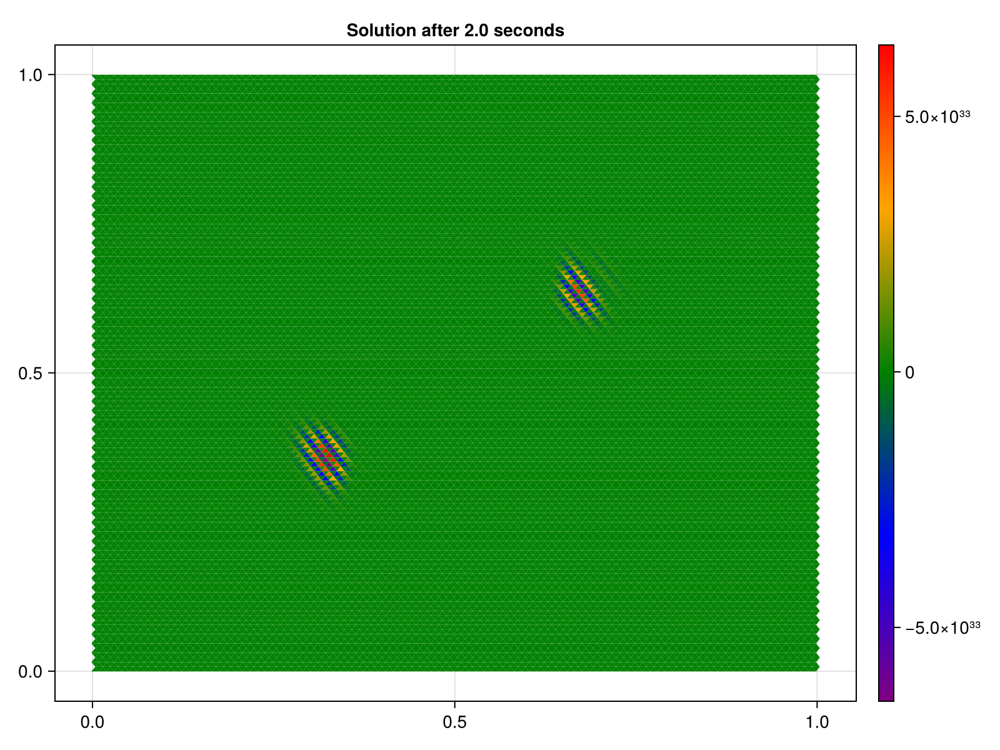

In [31]:
fig2

In [32]:
fig3 = Figure()
ax3 = Axis(fig3[1, 1])
aux = Cochain(u_initial_dual_0form.values - u.values, 0, false)
fig3,ax3 = plot_cochain(fig3, ax3, aux, problem.mesh, :rainbow)

(Scene (600px, 450px):
  0 Plots
  2 Child Scenes:
    ├ Scene (600px, 450px)
    └ Scene (600px, 450px), Axis (24576 plots))

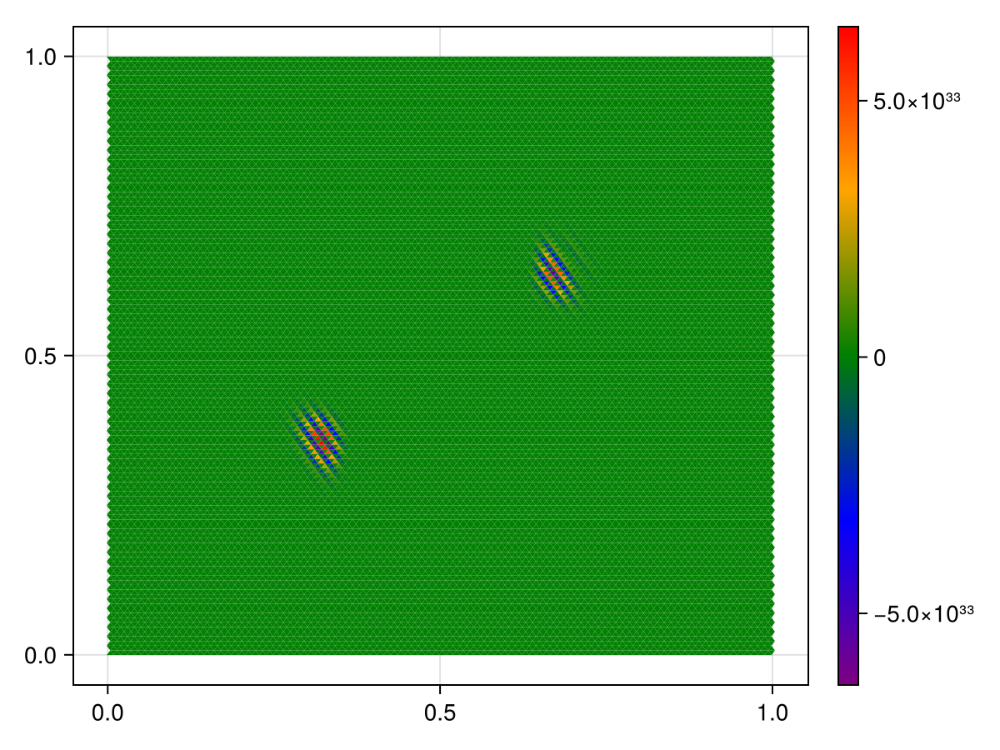

In [33]:
fig3